# Fase 4B CRISP-DM — Modelos de Deep Learning (CNN desde cero vs. MobileNetV2)

Compara directamente sobre exactamente las mismas particiones (`train / val / test`) las dos estrategias de Deep Learning contempladas en la sección 3 del enunciado:
1. **`SimpleFruitCNN` (entrenada desde cero):** 3 bloques `Conv2d-BatchNorm-ReLU-MaxPool` + `AdaptiveAvgPool2d` + capas densas con `Dropout`.
2. **`TransferMobileNetV2` (Transfer Learning):** backbone `MobileNetV2 (IMAGENET1K_V2)` completamente congelado (incluyendo estadísticas `BatchNorm` en modo `eval`) + cabeza densa propia (`1280 → 128 → 3`).

Ambas redes emplean **Data Augmentation** en entrenamiento, **entropía cruzada ponderada**, ajuste de `learning_rate` con el conjunto de validación y *early stopping*.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DIR_FIGURAS, DIR_METRICAS

report = json.loads((DIR_METRICAS / "resultados_completos.json").read_text(encoding="utf-8"))
rows = []
for name, info in report["models"].items():
    if info["family"] == "deep_learning":
        rows.append({
            "Modelo": name,
            "Entrada (px)": info["image_size"],
            "Params totales": info["params_info"]["total_params"],
            "Params entrenables": info["params_info"]["trainable_params"],
            "Mejor época": info["best_epoch"],
            "Train Macro-F1": info["train_macro_f1"],
            "Val Macro-F1": info["val_metrics"]["macro_f1"],
            "Test Macro-F1": info["test_metrics"]["macro_f1"],
            "Tiempo (s)": info["train_time_sec"],
            "Latencia (ms/img)": info["inference_ms_per_img"],
            "Peso disco (MB)": info["model_size_mb"],
            "Hiperparámetros": str(info["best_params"]),
        })
dl_df = pd.DataFrame(rows)
display(dl_df)

for name, info in report["models"].items():
    if info["family"] == "deep_learning":
        print(f"\nEnsayos de ajuste en validación — {name}:")
        display(pd.DataFrame(info["tuning_trials"]))

,Modelo,Entrada (px),Params totales,Params entrenables,Mejor época,Train Macro-F1,Val Macro-F1,Test Macro-F1,Tiempo (s),Latencia (ms/img),Peso disco (MB),Hiperparámetros
0,CNN simple (desde cero),128,101923,101923,17,0.8021,0.8342,0.8013,220.699,30.13,0.398,"{'learning_rate': 0.001, 'weight_decay': 0.000..."
1,MobileNetV2 (Transfer),224,2388227,164355,8,0.9466,0.9013,0.9382,352.355,35.44,9.340,"{'learning_rate': 0.001, 'weight_decay': 0.000..."



Ensayos de ajuste en validación — CNN simple (desde cero):


,lr,val_macro_f1,best_epoch
0,0.0010,0.834204,17
1,0.0003,0.819540,17



Ensayos de ajuste en validación — MobileNetV2 (Transfer):


,lr,weight_decay,val_macro_f1,best_epoch
0,0.0010,0.0001,0.901315,8
1,0.0003,0.0005,0.896751,8


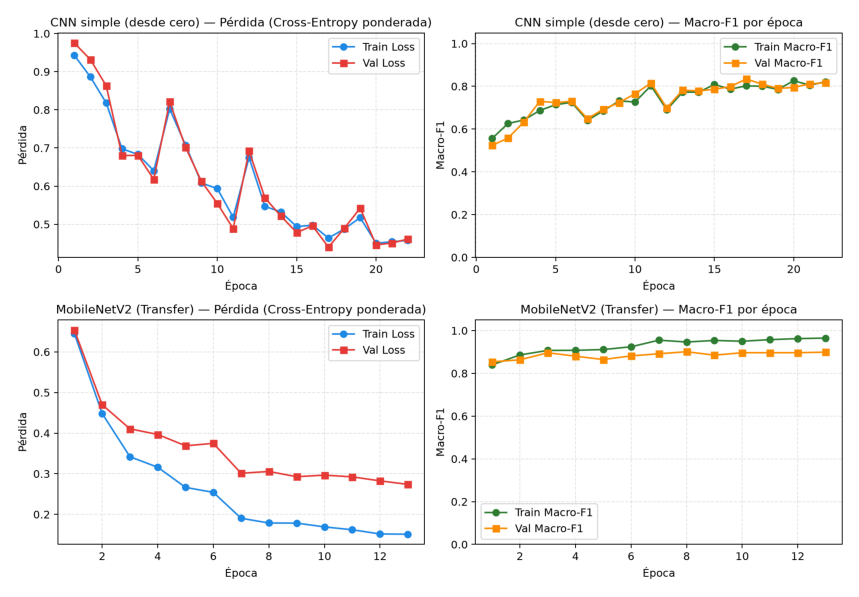

In [2]:
# Curvas de pérdida y Macro-F1 época por época (diagnóstico de sobreajuste)
curves_path = DIR_FIGURAS / "03_curvas_aprendizaje_dl.png"
plt.figure(figsize=(11, 7.5))
plt.imshow(Image.open(curves_path))
plt.axis("off")
plt.show()

In [3]:
# Desempeño de modelos Deep Learning por origen en prueba (diagnóstico de domain shift)
dl_src_rows = []
for name, info in report["models"].items():
    if info["family"] == "deep_learning":
        for src, vals in info["test_by_source"].items():
            dl_src_rows.append({
                "Modelo": name,
                "Origen": src,
                "n": vals["n"],
                "Exactitud": vals["accuracy"],
                "Macro-F1 (presentes)": vals["macro_f1_present_classes"],
            })
display(pd.DataFrame(dl_src_rows).pivot(index="Modelo", columns="Origen", values=["Exactitud", "Macro-F1 (presentes)"]))

Exactitud                                    \
Origen                  FruitNet_Kaggle FruitNet_Mixed_Segmentada  Propia   
Modelo                                                                      
CNN simple (desde cero)          0.8362                    0.9412  0.8033   
MobileNetV2 (Transfer)           0.9741                    1.0000  0.8689   

                        Macro-F1 (presentes)                                    
Origen                       FruitNet_Kaggle FruitNet_Mixed_Segmentada  Propia  
Modelo                                                                          
CNN simple (desde cero)               0.8342                    0.9697  0.5481  
MobileNetV2 (Transfer)                0.9700                    1.0000  0.5901

### Discusión crítica y comparación con literatura (Fase 4B)
- **Regularización efectiva frente a ML clásico:** La combinación de *Data Augmentation* geométrico/cromático, `Dropout`, `weight_decay`, entropía cruzada ponderada y *early stopping* por `Val Macro-F1` reduce drásticamente el sobreajuste: la brecha `Train−Test` baja a **`0.0008`** en `SimpleFruitCNN` y **`0.0084`** en `MobileNetV2 (Transfer)` (frente a `0.21–0.26` en ML clásico).
- **Transfer Learning vs. entrenamiento desde cero:** Congelar el extractor `MobileNetV2 (IMAGENET1K_V2)` dejando las capas `BatchNorm` en `eval()` permite entrenar solo `164,355` parámetros de la cabeza densa y alcanzar **`Test Macro-F1 = 0.9382`** (`+0.1369` sobre `SimpleFruitCNN`), manteniendo **`35.44 ms/img`** en CPU (Sandler et al., *IEEE CVPR 2018*; Kornblith et al., *IEEE CVPR 2019*).
- **Hallazgo de *domain shift* / *shortcut learning*:** Pese al `0.9382` global, al desglosar por origen `MobileNetV2` obtiene `100 %` en `FruitNet_Mixed_Segmentada` (`n=17`, todas `Regular`, `52×55 px`), `97.41 %` en `FruitNet_Kaggle` (`n=116`) y `86.89 %` de exactitud (`Macro-F1 = 0.5901`) en `Propia` (`n=61`). Este fenómeno coincide con el *shortcut learning* descrito por Geirhos et al. (*Nature Machine Intelligence*, 2020), y se analiza error por error en la Fase 5.